# Tema : Modelos ARCH/GARCH
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

In [1]:
# Instalar todas las librerias necesarias previamente desde r-requirements.txt
suppressPackageStartupMessages({
  # Datos
  library(tidyverse)
  library(tidyquant)   # Descarga de precios de Yahoo Finance en formato tidy (quantmod, xts)
  library(zoo)         # Ventanas móviles

  # Modelos de volatilidad
  library(rugarch)     # Modelos ARCH/GARCH univariados
  library(FinTS)       # Prueba ARCH LM de Engle

  # Estadísticos
  library(tseries)     # Pruebas ADF, KPSS y Jarque-Bera
  library(forecast)    # ggAcf, ggPacf
  library(ggtime)
  library(patchwork)
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

### Ejercicio 1. Modelación de los precios de Google.

Usando los datos de precios de cierre de Google en la bolsa de valores, estimar un modelo ARCH/GARCH

fecha,precio
<date>,<dbl>
2021-01-04,85.60123
2021-01-05,86.22927
2021-01-06,85.95040
2021-01-07,88.52405
2021-01-08,89.51266
2021-01-11,87.50716


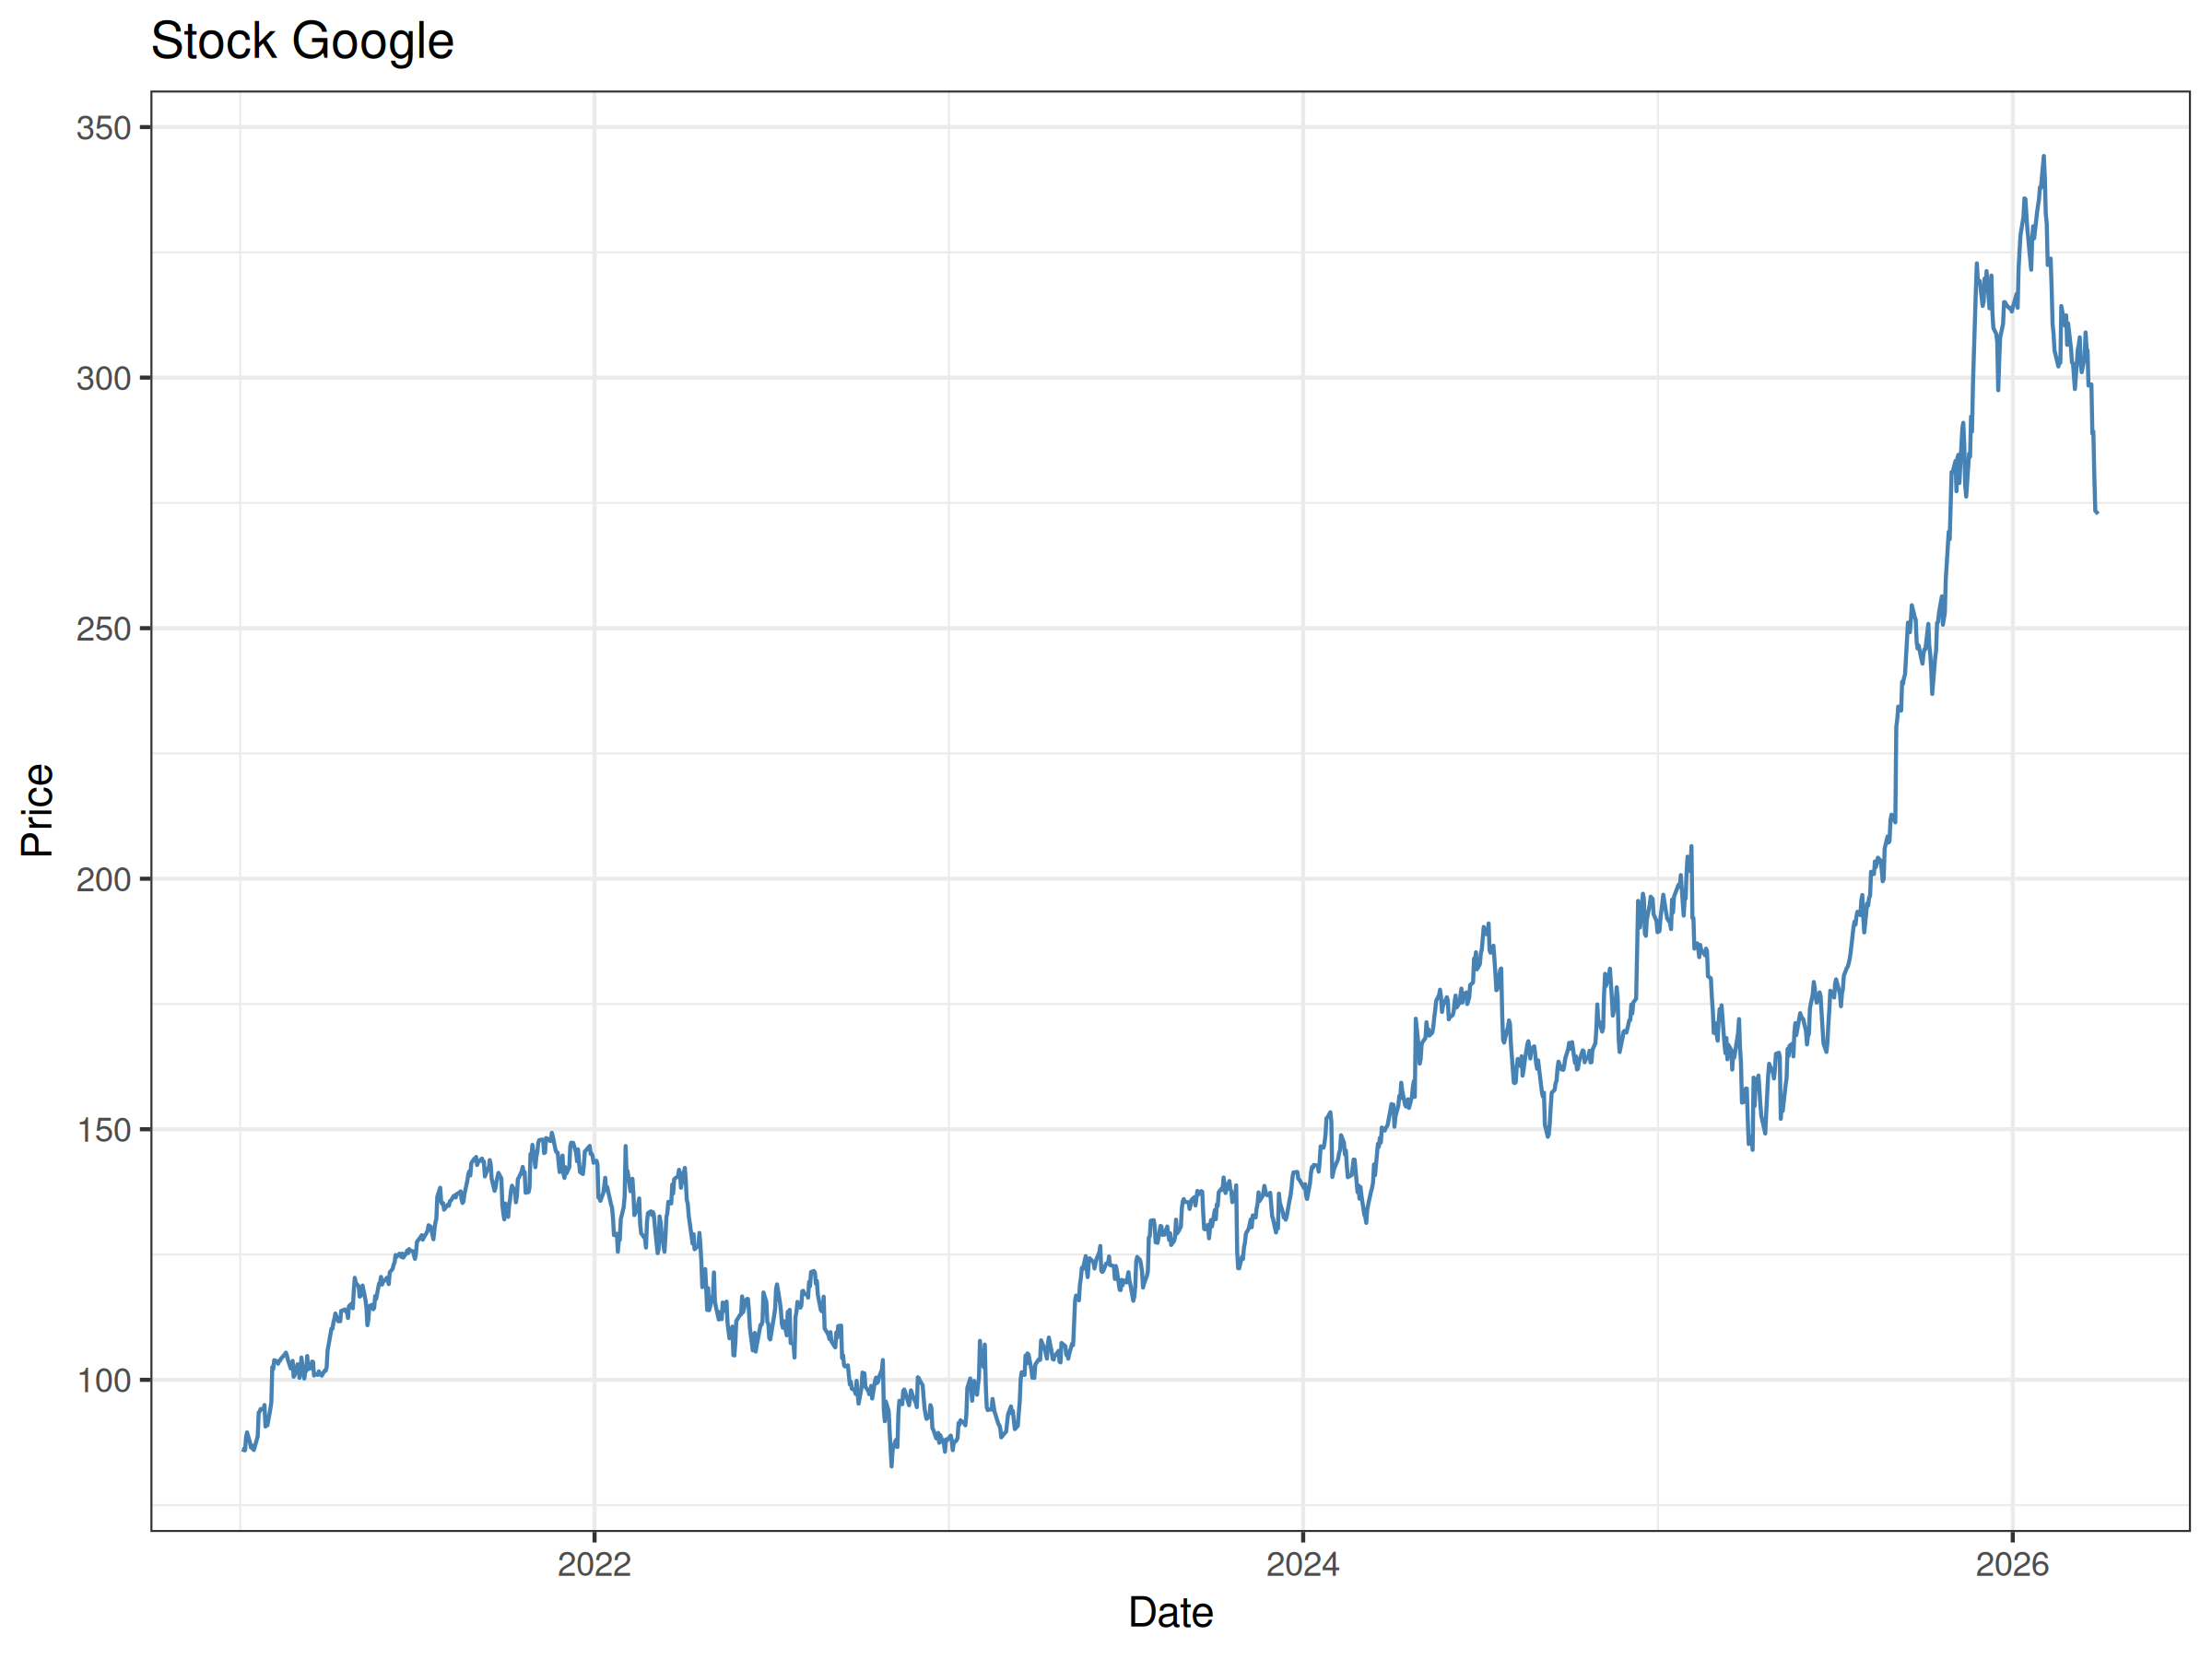

In [2]:
# Descargar datos de la serie de tiempo (precio de cierre ajustado)
price_google <- tq_get("GOOG", get = "stock.prices",
                       from = "2021-01-01", to = "2026-03-31") |>
  select(fecha = date, precio = adjusted)

head(price_google)

price_google |>
  ggplot(aes(fecha, precio)) +
  geom_line(colour = "steelblue") +
  labs(title = "Stock Google", x = "Date", y = "Price")

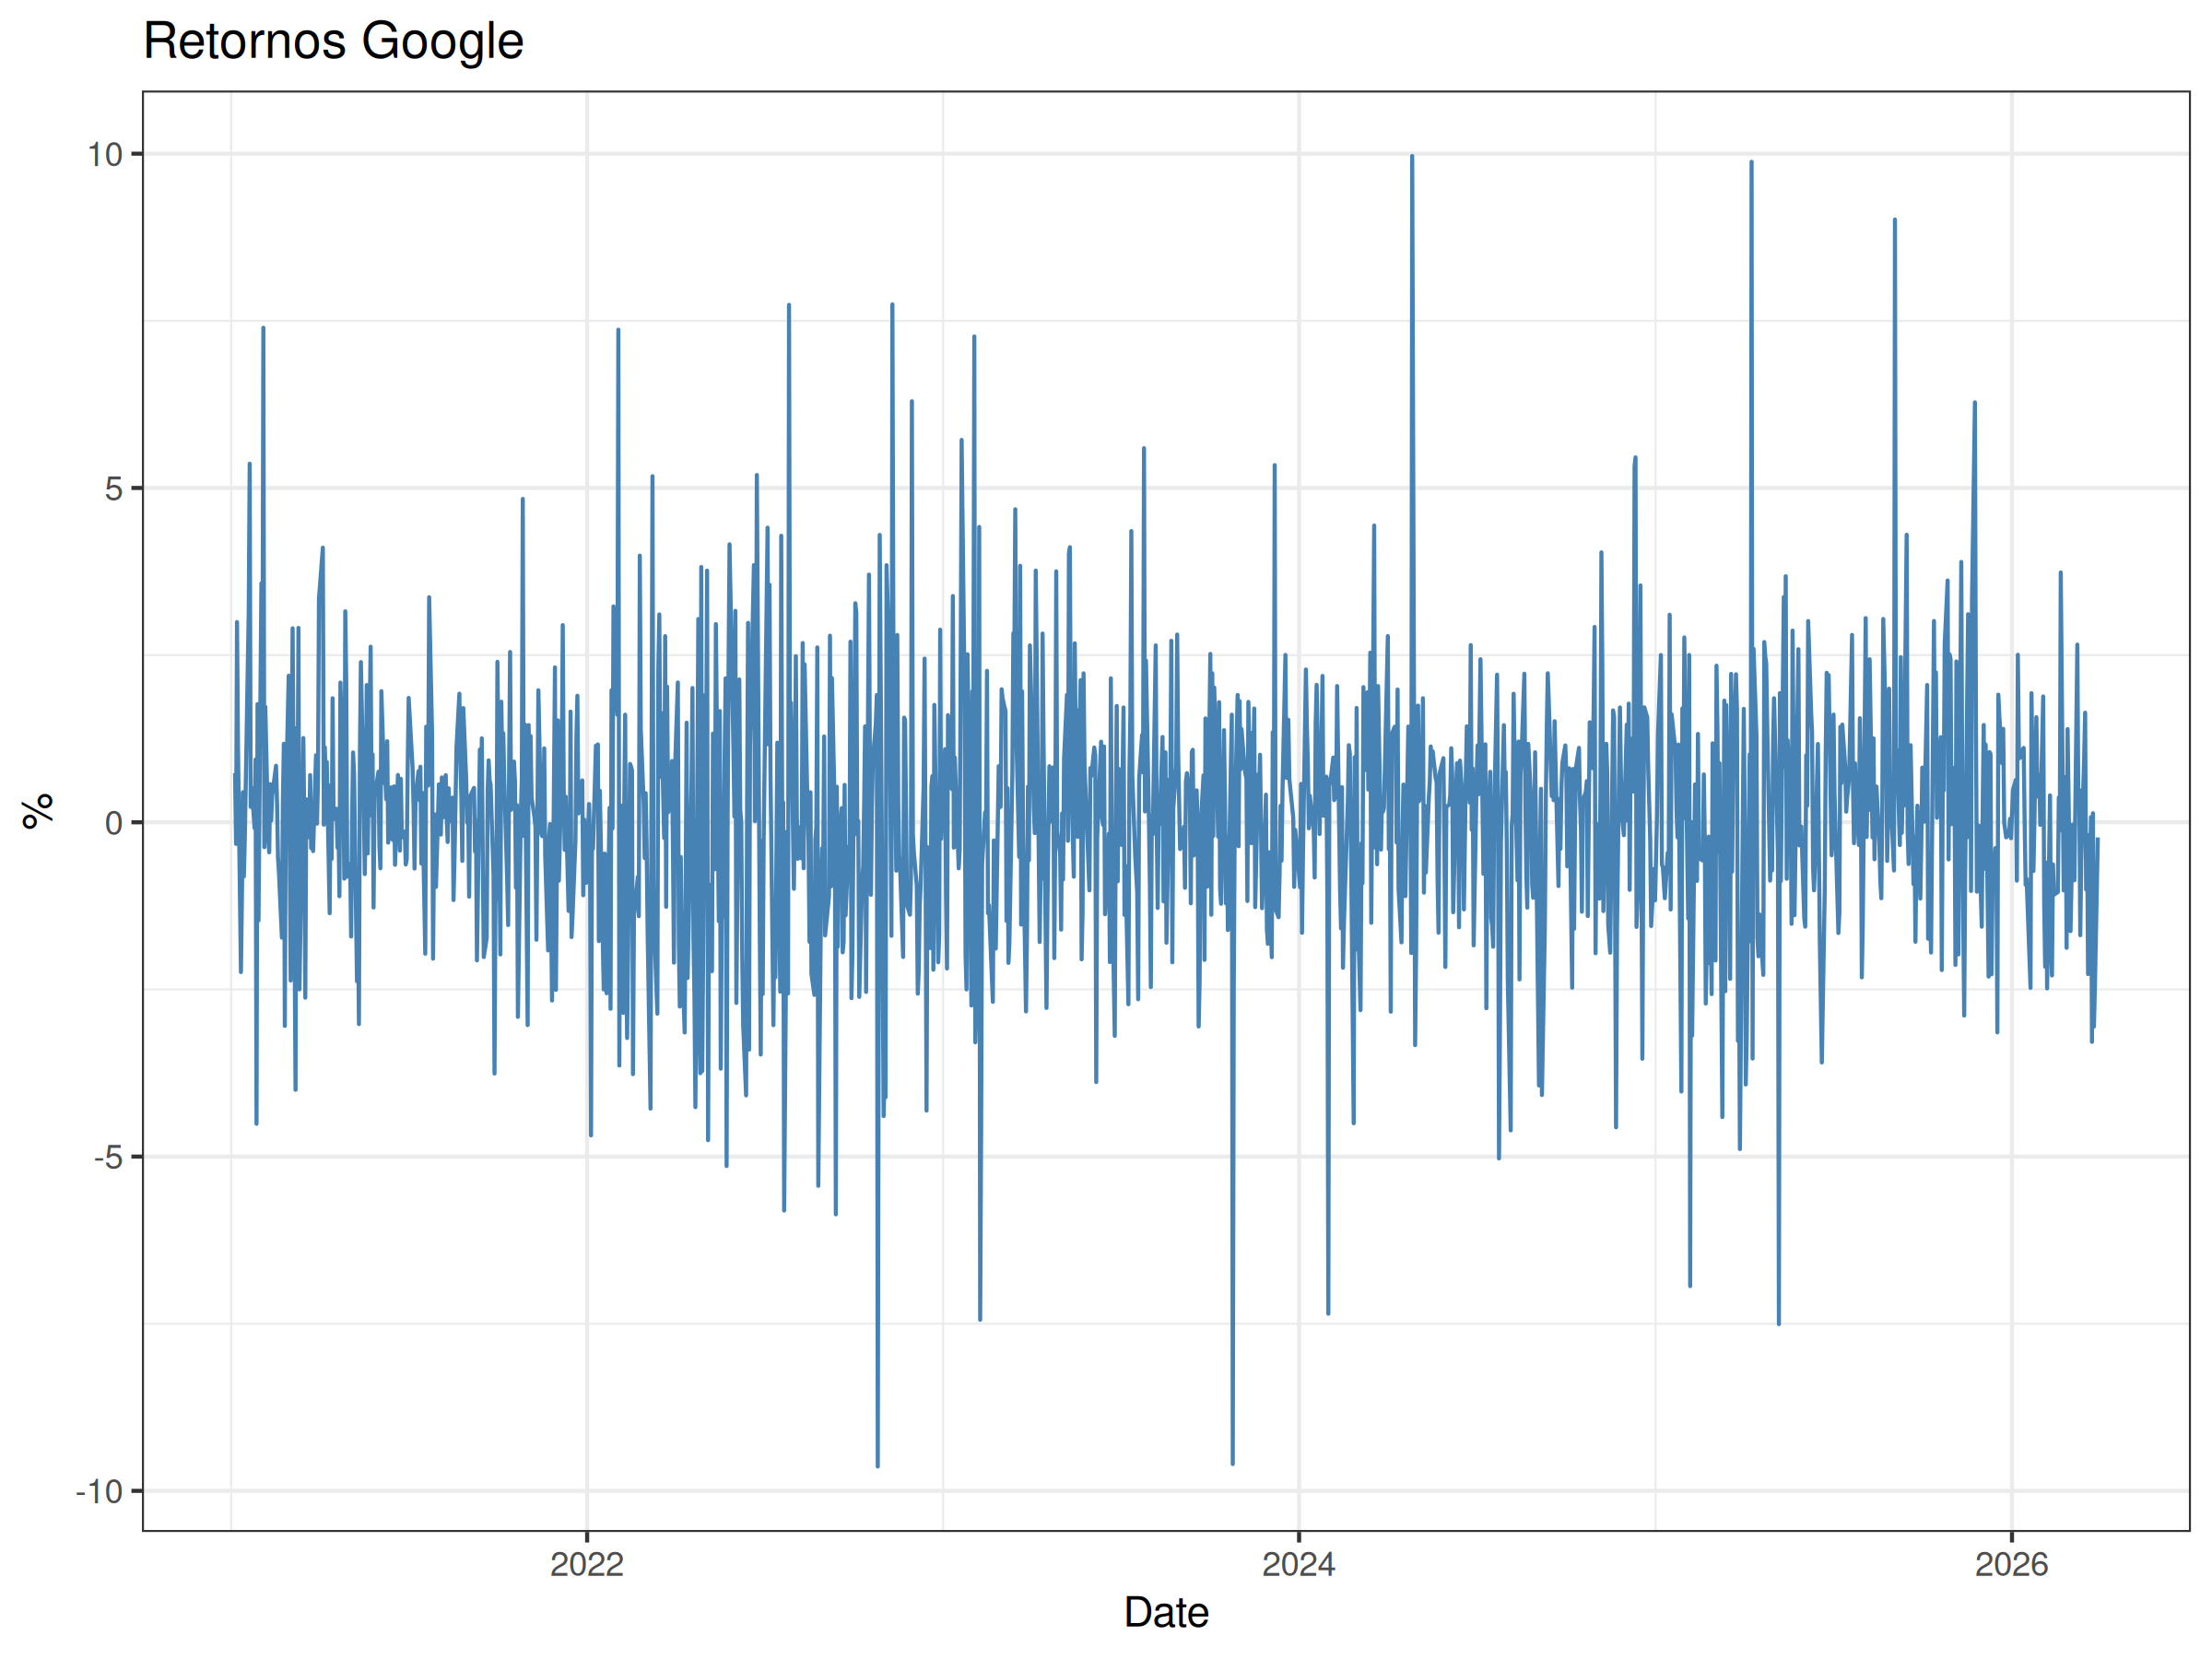

In [3]:
# retornos porcentuales diarios
retornos <- price_google |>
  mutate(retorno = 100 * (precio / lag(precio) - 1)) |>
  filter(!is.na(retorno))

retornos |>
  ggplot(aes(fecha, retorno)) +
  geom_line(colour = "steelblue") +
  labs(title = "Retornos Google", x = "Date", y = "%")

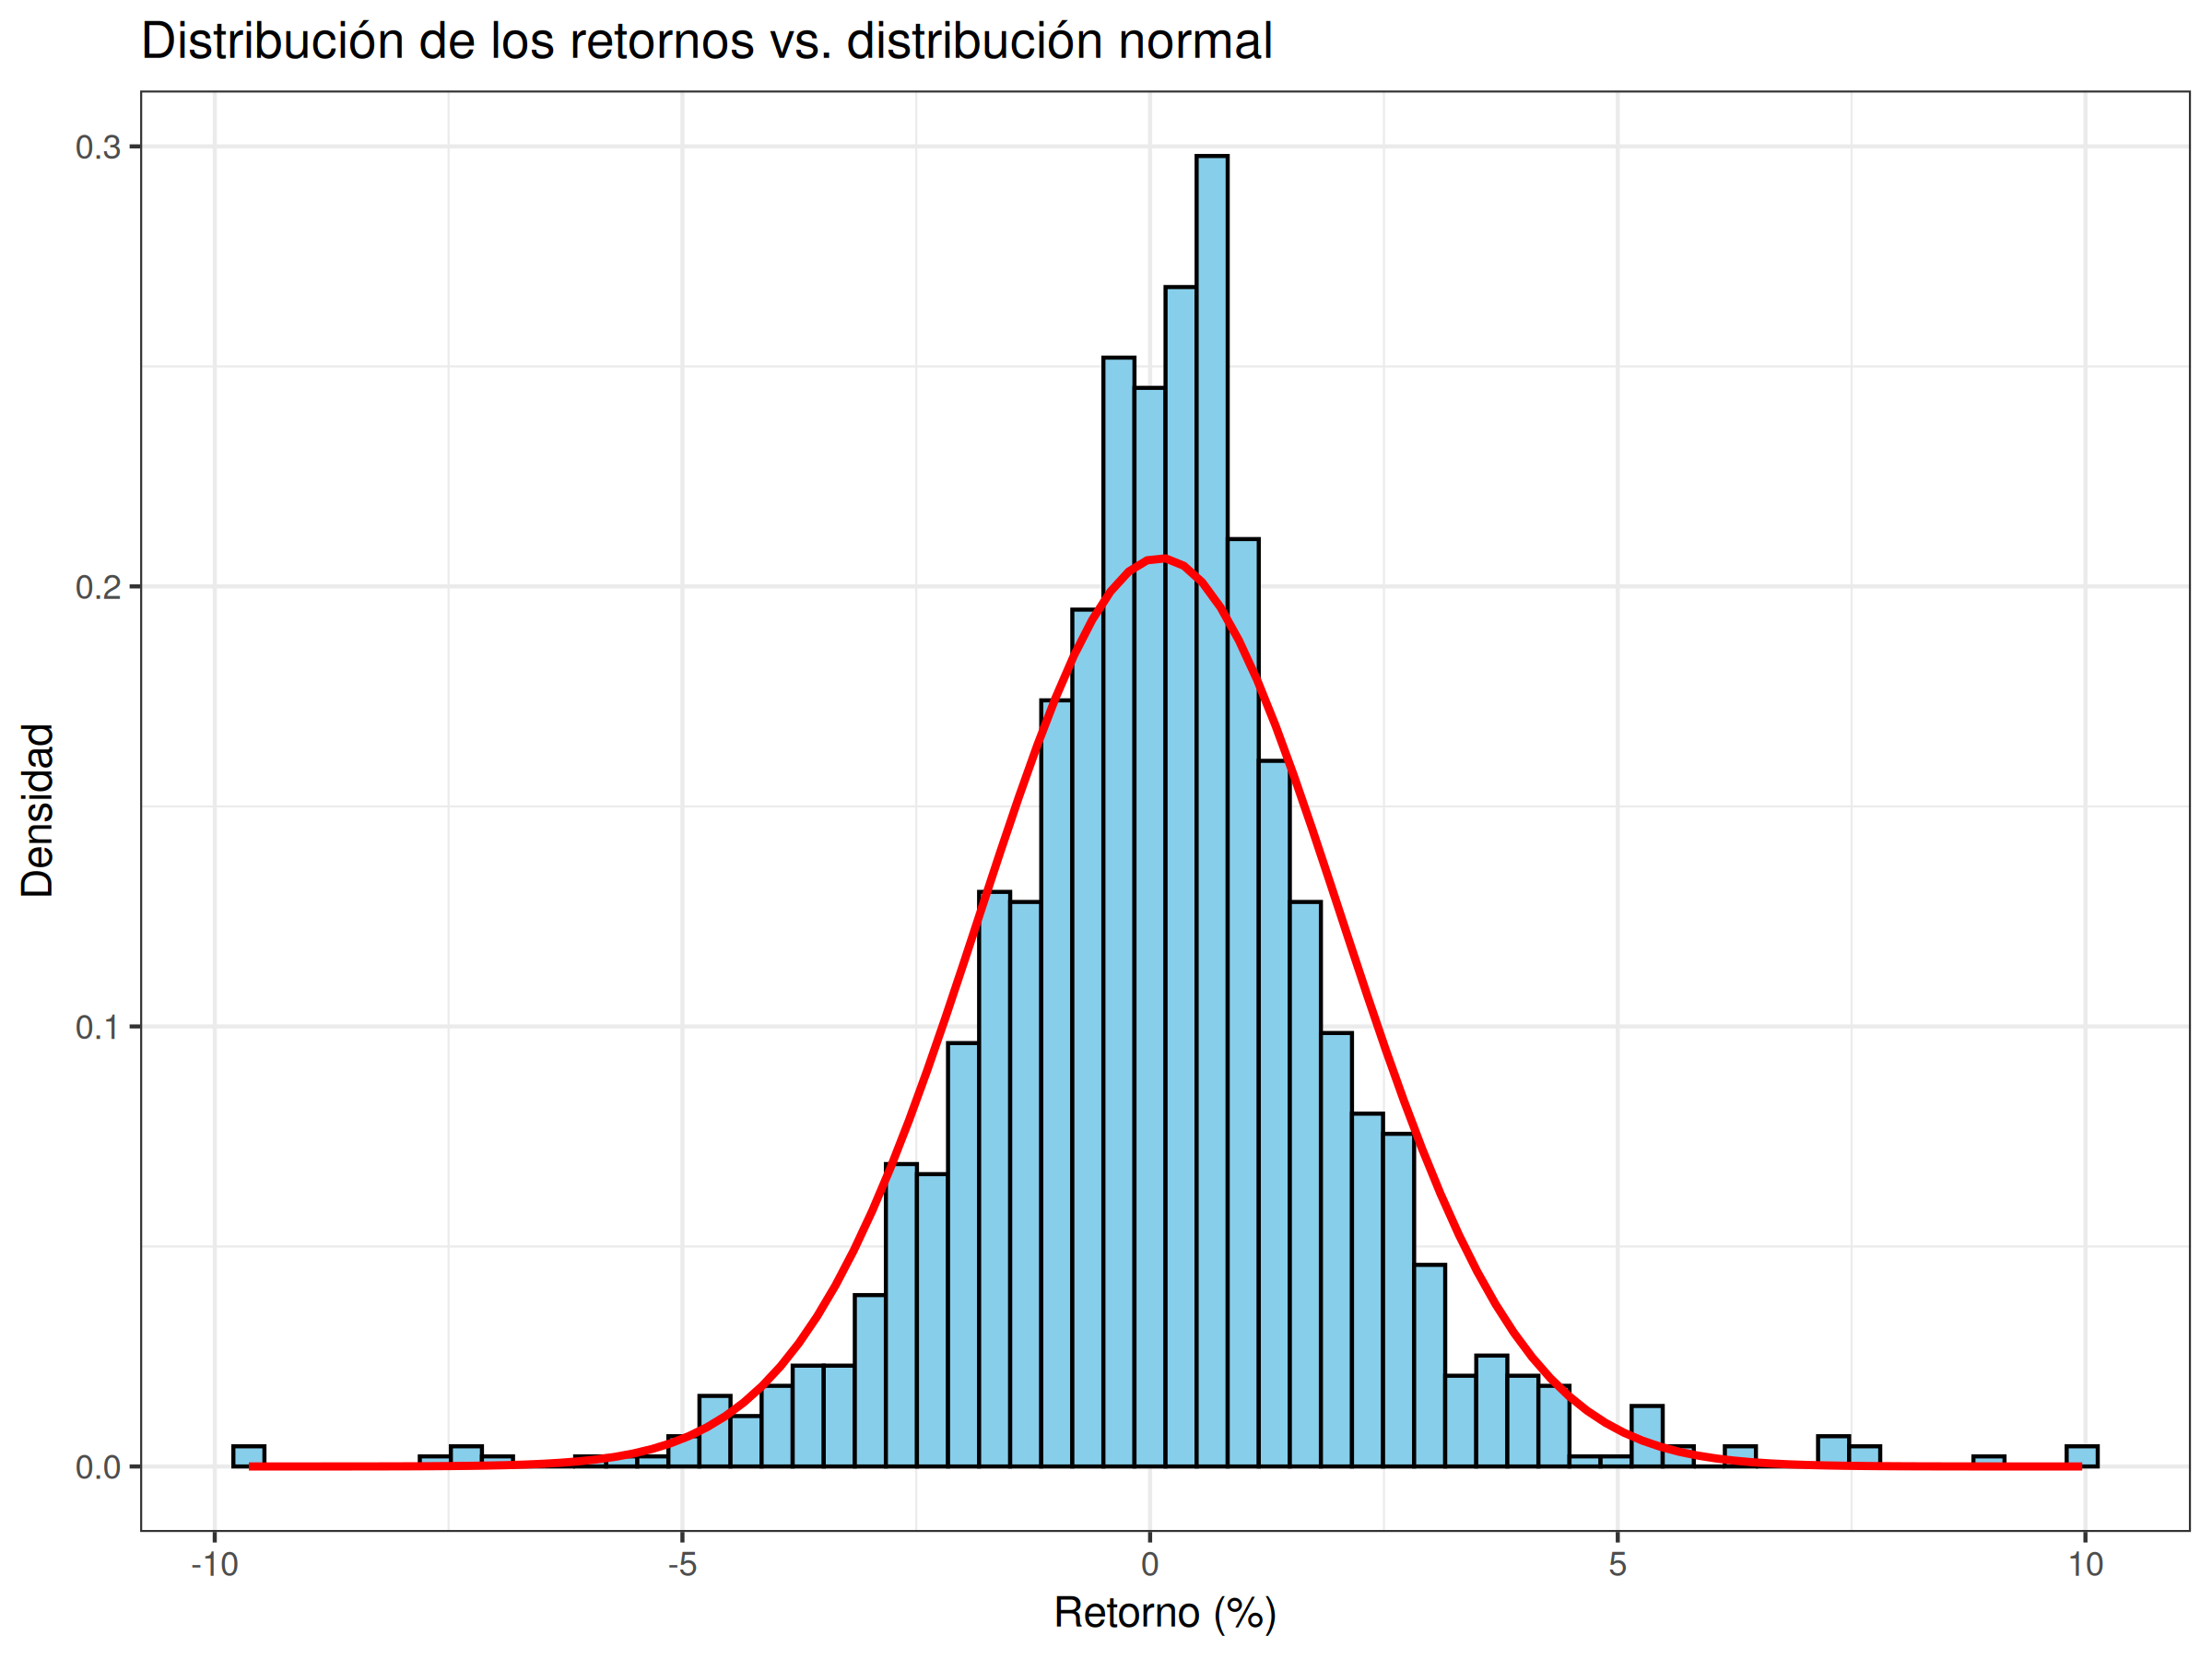

In [4]:
# Distribución de los retornos. Suelen tener colas largas.
retornos |>
  ggplot(aes(retorno)) +
  geom_histogram(aes(y = after_stat(density)), bins = 60, fill = "skyblue", colour = "black") +
  stat_function(fun = dnorm,
                args = list(mean = mean(retornos$retorno), sd = sd(retornos$retorno)),
                colour = "red", linewidth = 1) +
  labs(title = "Distribución de los retornos vs. distribución normal", x = "Retorno (%)", y = "Densidad")

In [5]:
# Test de normalidad Jarque-Bera
test_normalidad <- function(datos, titulo = "Prueba de normalidad") {
  datos <- as.numeric(na.omit(datos))
  jb    <- jarque.bera.test(datos)

  cat(strrep("=", 80), "\n", titulo, "\n", strrep("=", 80), "\n", sep = "")
  cat("Estadístico Jarque-Bera:", round(jb$statistic, 4), "\n")
  cat("p-valor:", format.pval(jb$p.value, digits = 4), "\n")

  # Interpretación
  if (jb$p.value < 0.05) {
    cat("Resultado: Se rechaza la normalidad (p < 0.05).\n")
    cat("Los datos tienen exceso de curtosis o asimetría.\n")
  } else {
    cat("Resultado: No se rechaza la normalidad. Los datos son aproximadamente normales.\n")
  }
  cat(strrep("=", 80), "\n")
}

test_normalidad(retornos$retorno)

Prueba de normalidad
Estadístico Jarque-Bera: 589.1672 
p-valor: < 2.2e-16 
Resultado: Se rechaza la normalidad (p < 0.05).
Los datos tienen exceso de curtosis o asimetría.


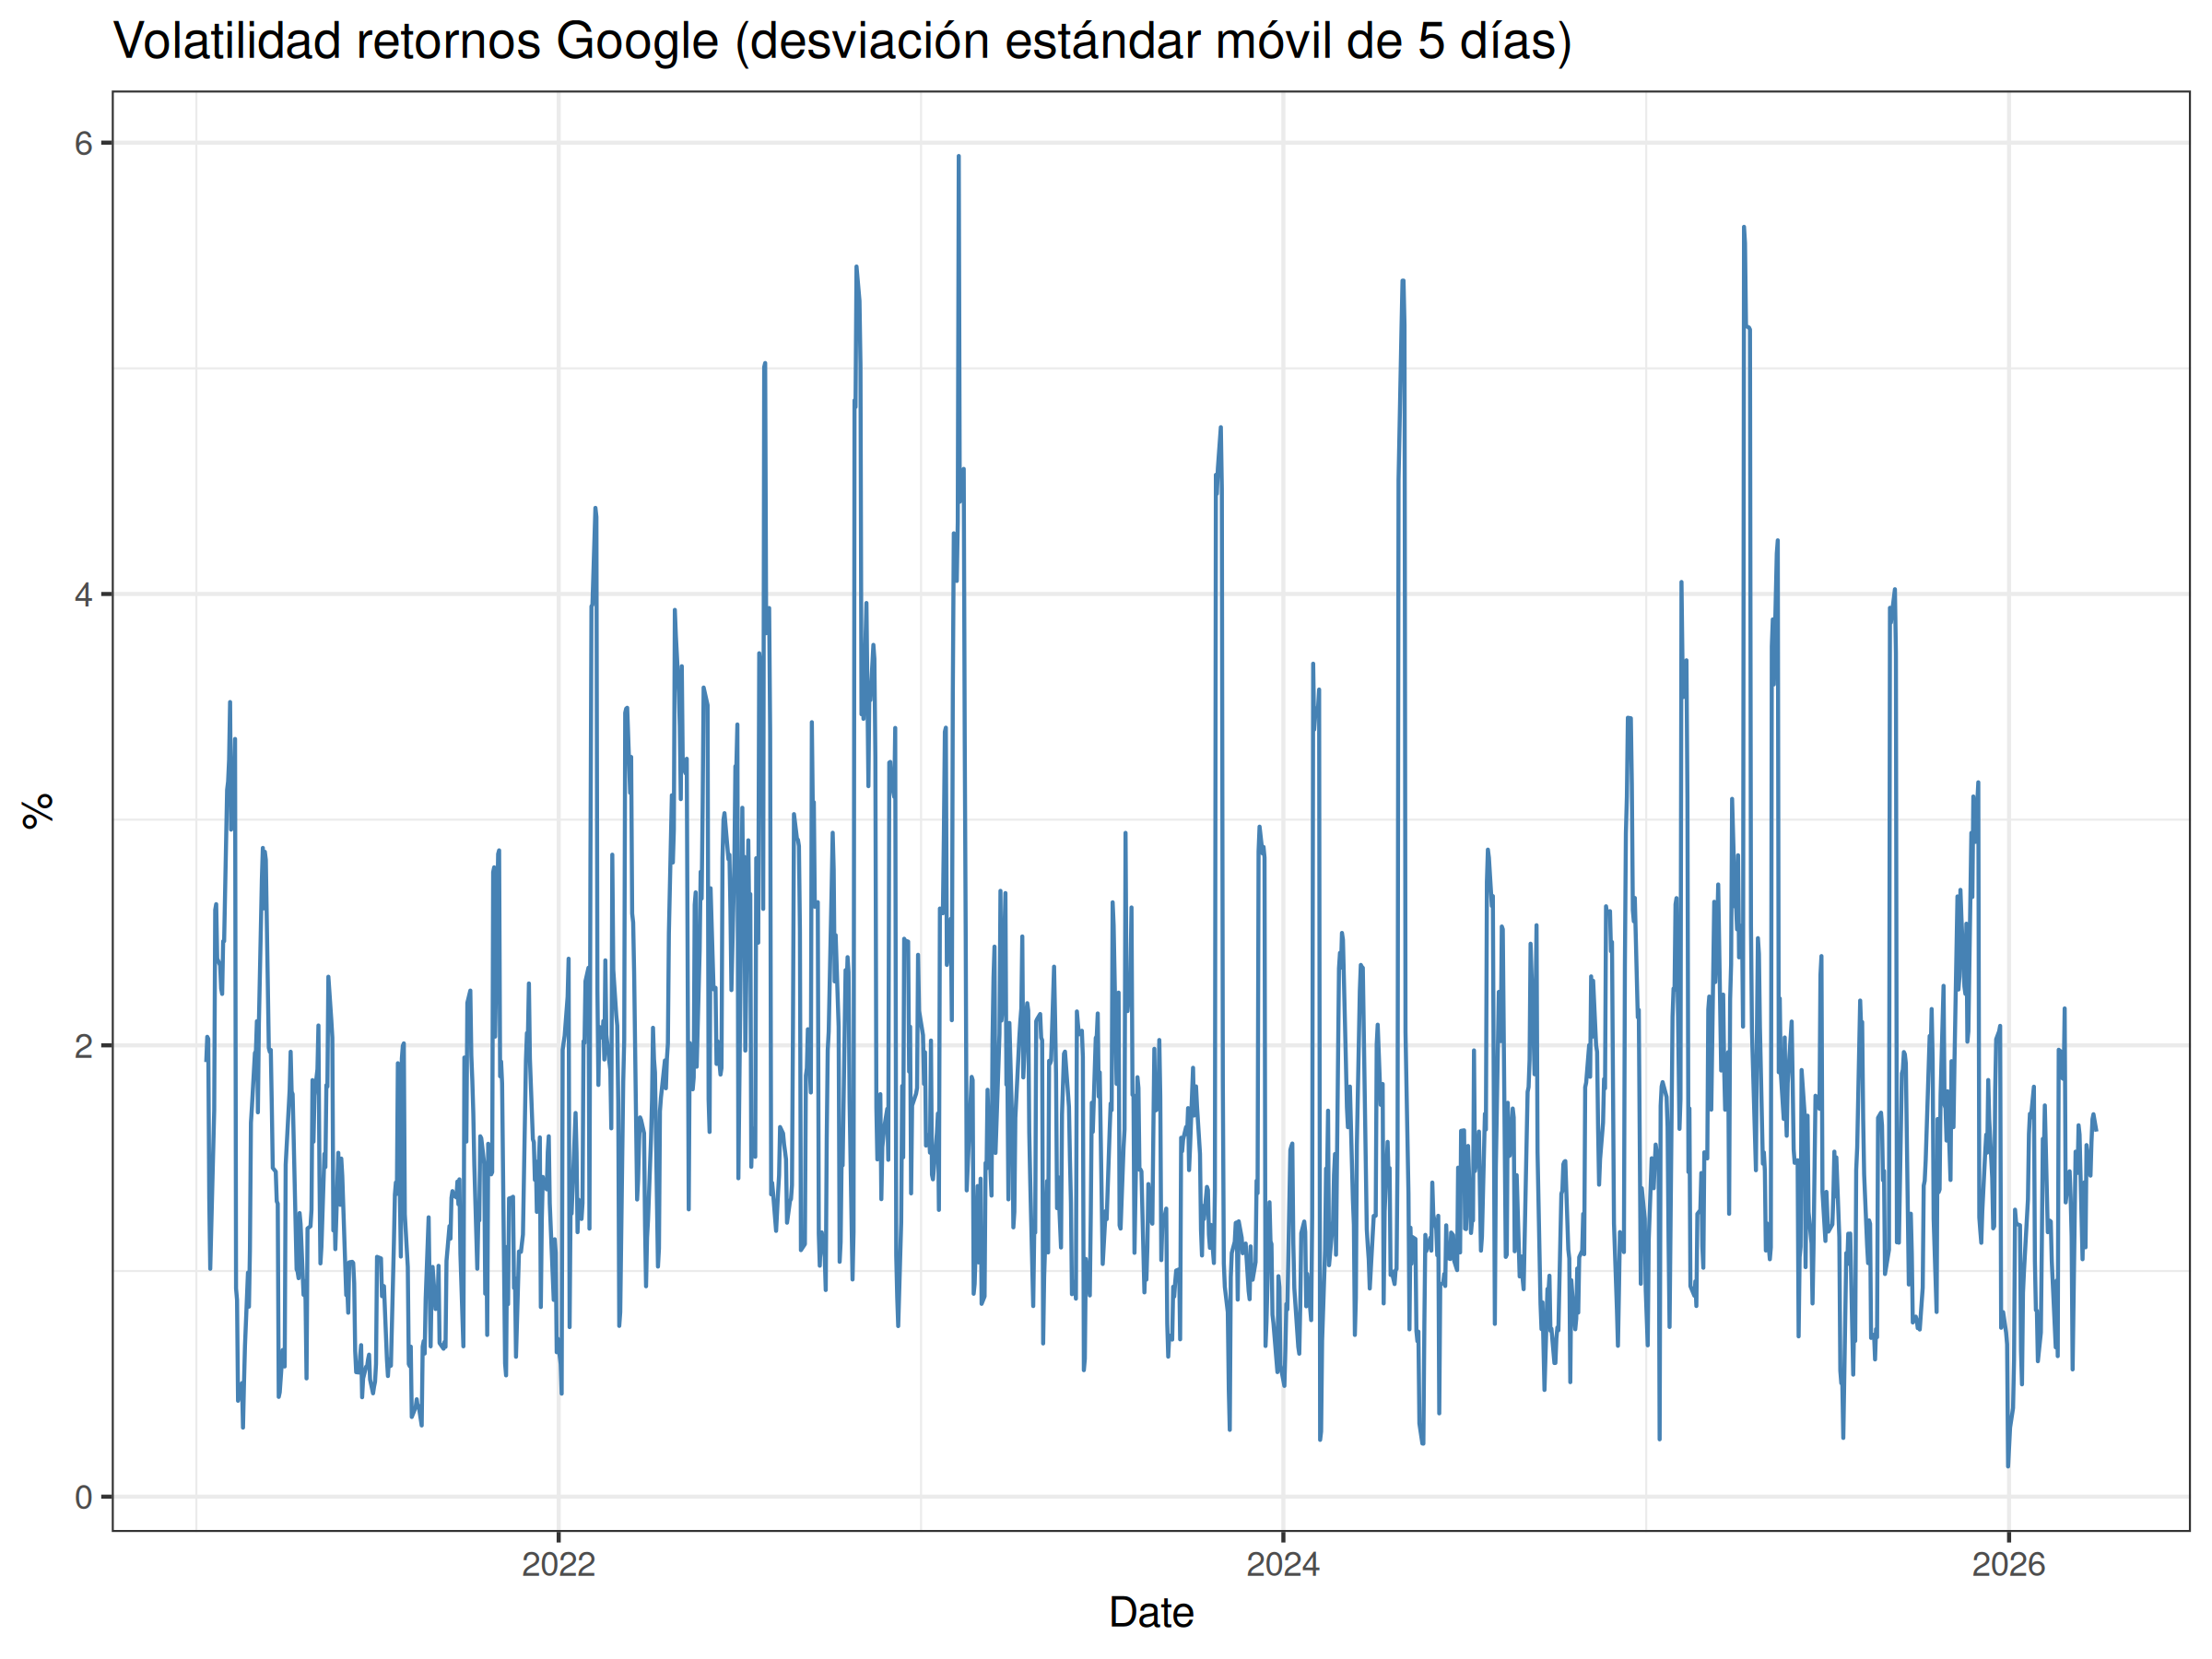

In [6]:
# Estimar de volatilidad: Inspección visual de la desviación estándar móvil de los retornos
# ventana semanal (5 días hábiles)
ventana <- 5

retornos |>
  mutate(volatilidad_movil = rollapply(retorno, width = ventana, FUN = sd,
                                       fill = NA, align = "right")) |>
  filter(!is.na(volatilidad_movil)) |>
  ggplot(aes(fecha, volatilidad_movil)) +
  geom_line(colour = "steelblue") +
  labs(title = "Volatilidad retornos Google (desviación estándar móvil de 5 días)",
       x = "Date", y = "%")

In [7]:
# Prueba de Dickey-Fuller Aumentada (ADF) y KPSS: Verifica que los retornos sean estacionarios
test_estacionariedad <- function(datos) {
  datos <- as.numeric(na.omit(datos))
  adf_result  <- suppressWarnings(adf.test(datos))
  kpss_result <- suppressWarnings(kpss.test(datos, null = "Level"))

  tibble(
    Test         = c("Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"),
    Estadistico  = round(c(adf_result$statistic, kpss_result$statistic), 4),
    `P-valor`    = round(c(adf_result$p.value, kpss_result$p.value), 4),
    Estacionario = c(if_else(adf_result$p.value < 0.05, "Sí", "No"),
                     if_else(kpss_result$p.value < 0.05, "No", "Sí"))
  )
}

test_estacionariedad(retornos$retorno)

Test,Estadistico,P-valor,Estacionario
<chr>,<dbl>,<dbl>,<chr>
Prueba Augmented Dickey-Fuller (ADF),-10.6879,0.01,Sí
Prueba KPSS,0.1071,0.10,Sí


In [8]:
# Prueba de Multiplicador de Lagrange (LM) de Engle

# Pasos :
# Ajusta un modelo de media (por ejemplo, ARIMA o regresión) a tu serie temporal y extrae los residuos.
# Elige el número de retardos para la regresión auxiliar normalmente 5 (una semana) o 10 (dos semanas).
# Regresión auxiliar: e_t^2 = a0 + a1 e_{t-1}^2 + ... + aq e_{t-q}^2 + u_t
# Estadístico LM = n * R^2 ~ Chi-cuadrado(q)

# Notas interpretacion :
# Valor p > 0,05: No se rechaza H0. No hay evidencia sólida de efectos ARCH; un modelo de varianza constante podría ser adecuado.
# Valor p ≤ 0,05: Se rechaza H0. Hay efectos ARCH presentes. Considere ajustar un modelo GARCH o EGARCH para modelar explícitamente la varianza variable en el tiempo.
# Elección de retardos: Por defecto, se suelen usar 5 retardos para datos diarios o 10 retardos para datos de mayor frecuencia.
# Tamaño del efecto: Un estadístico LM grande indica una agrupación de volatilidad más pronunciada.

# Modelo de media AR(1) y sus residuos
model_fit <- arima(retornos$retorno, order = c(1, 0, 0))
residuos  <- residuals(model_fit)

# Aplicar test Engle ARCH sobre residuos (lag = 5 o lag = 10 usualmente)
result <- ArchTest(residuos, lags = 5)
print(result)

result_10 <- ArchTest(residuos, lags = 10)
print(result_10)


	ARCH LM-test; Null hypothesis: no ARCH effects

data:  residuos
Chi-squared = 13.601, df = 5, p-value = 0.01835




	ARCH LM-test; Null hypothesis: no ARCH effects

data:  residuos
Chi-squared = 15.414, df = 10, p-value = 0.1177



**Interpretación**

- La función `ArchTest()` del paquete `FinTS` calcula la prueba LM de Engle con la regresión auxiliar de los residuos al cuadrado. La hipótesis nula es que no hay efectos ARCH.
- Con 5 rezagos el estadístico es 13.60 con un p-valor de 0.018, por lo que se rechaza $H_0$ y hay evidencia de efectos ARCH en los residuos del modelo de media AR(1).
- Con 10 rezagos el estadístico es 15.41 con un p-valor de 0.118, por lo que no se rechaza $H_0$. Al agregar rezagos que aportan poca información la prueba pierde potencia, por eso conviene revisar también la ACF y la prueba de Ljung-Box de los residuos al cuadrado.

lag,lb_stat,lb_pvalue
<int>,<dbl>,<dbl>
1,3.547766,0.059625690
2,3.714614,0.156092402
3,8.149715,0.043016784
4,13.425095,0.009375091
5,15.432947,0.008664081
6,15.726405,0.015300282
7,17.351676,0.015263962
8,18.423295,0.018267484
9,18.620299,0.028622110


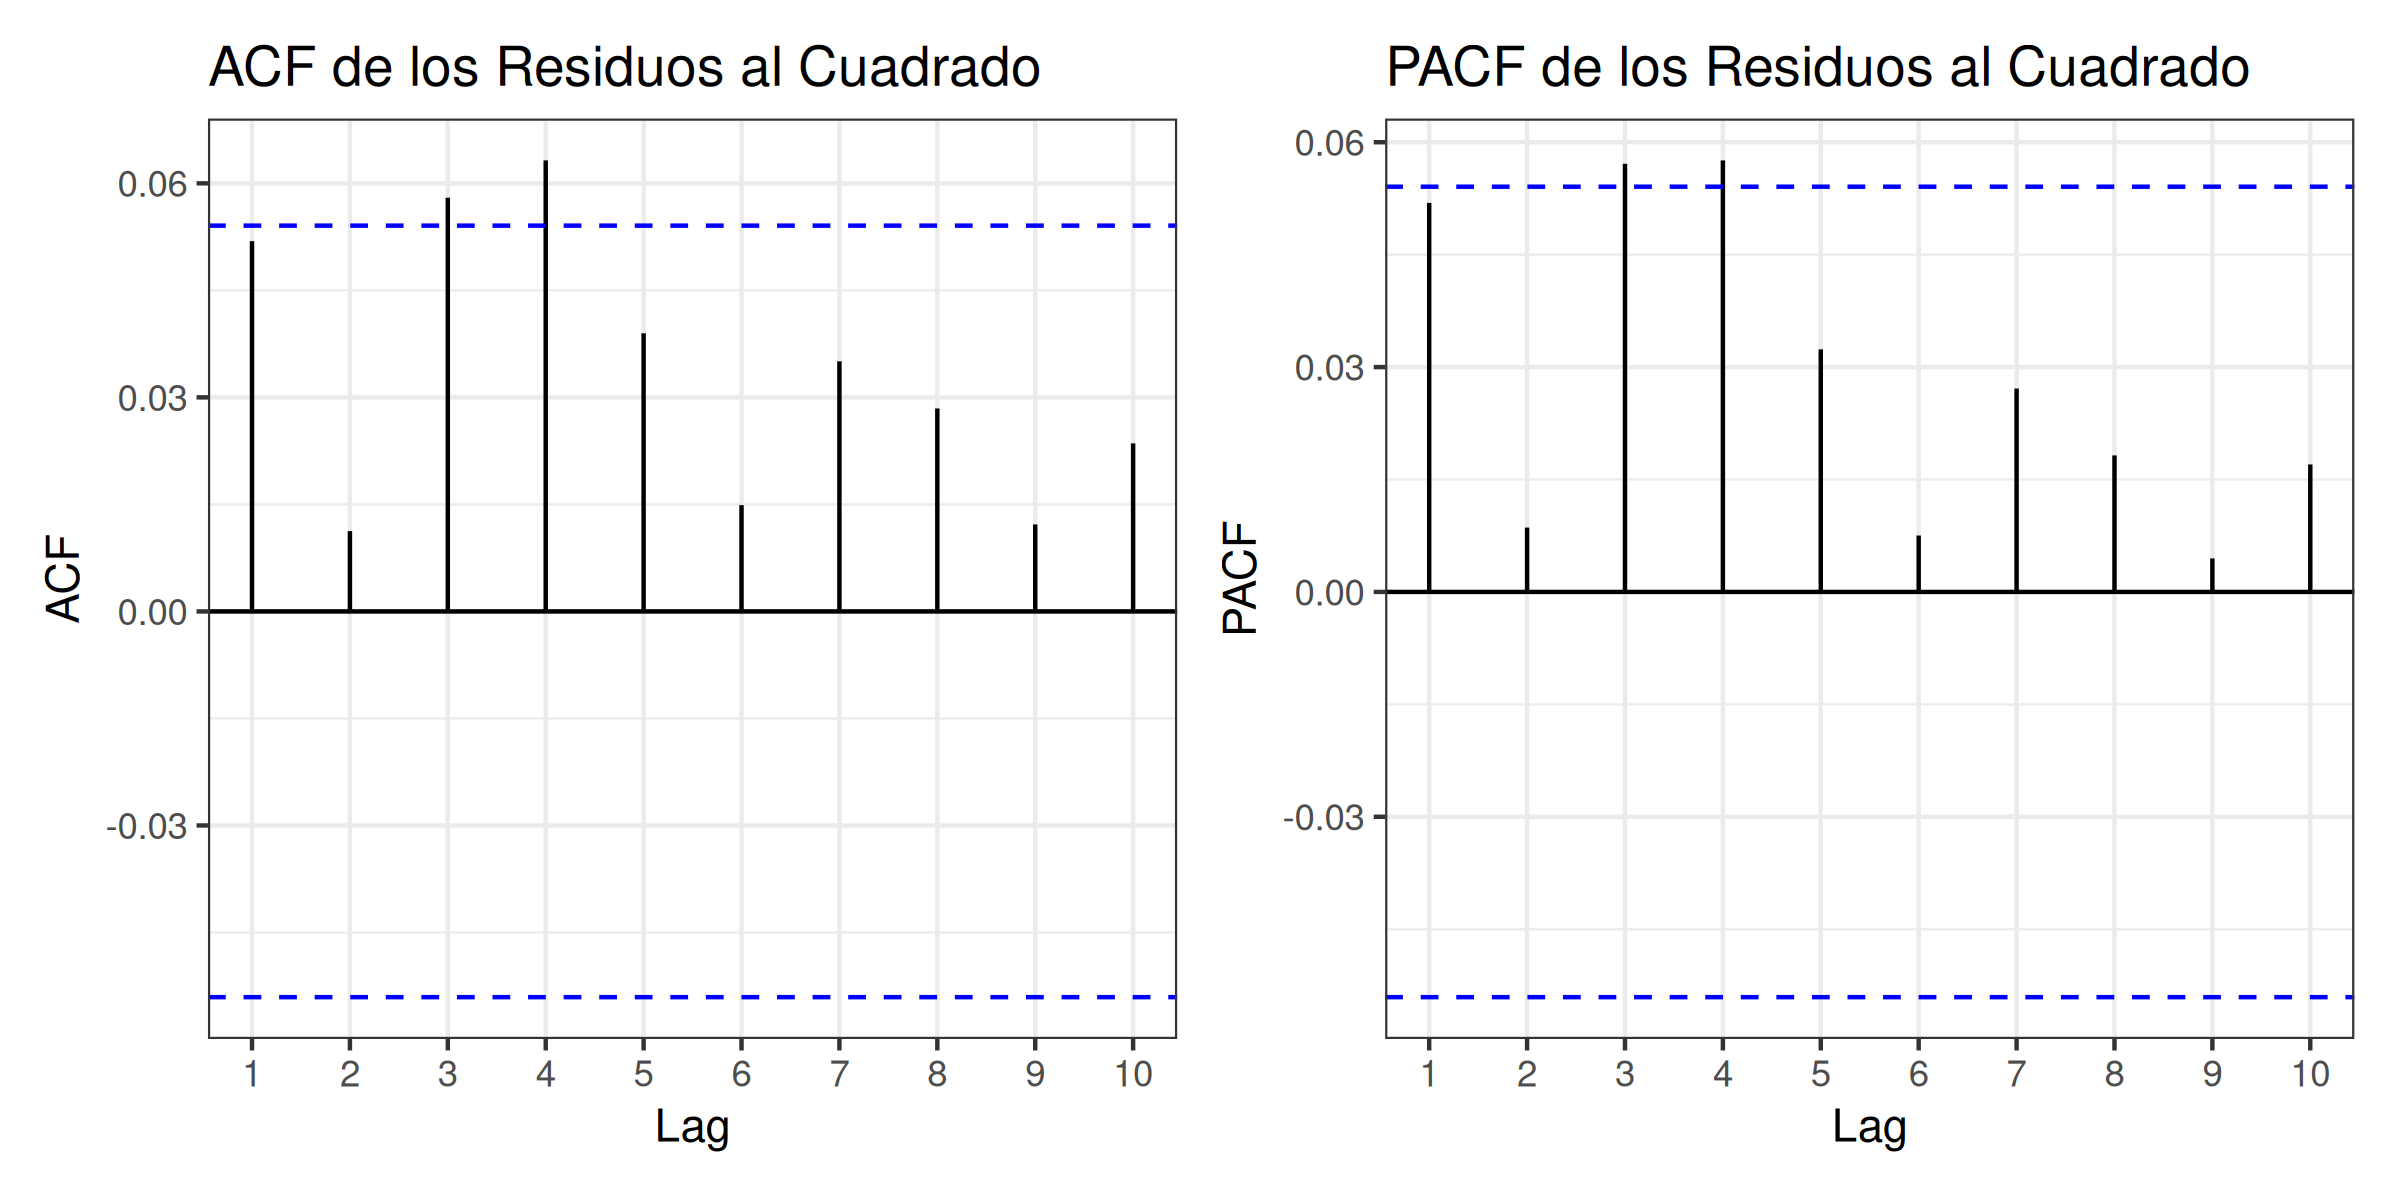

In [9]:
# Visualizar ACF y PACF de residuos al cuadrado
options(repr.plot.height = 4)
(ggAcf(residuos^2, lag.max = 10) + labs(title = "ACF de los Residuos al Cuadrado")) |
  (ggPacf(residuos^2, lag.max = 10) + labs(title = "PACF de los Residuos al Cuadrado"))
options(repr.plot.height = 6)

# Ljung-Box test autocorrelacion de los residuos al cuadrado
map_dfr(1:10, \(k) {
  lb <- Box.test(residuos^2, lag = k, type = "Ljung-Box")
  tibble(lag = k, lb_stat = unname(lb$statistic), lb_pvalue = lb$p.value)
})

**Interpretación**

- La prueba de Ljung-Box sobre los residuos al cuadrado rechaza la ausencia de autocorrelación a partir del rezago 3: la volatilidad de hoy depende de la de días anteriores (agrupamiento de volatilidad). Esto justifica un modelo de varianza condicional.

## Modelo ARCH/GARCH

Para modelizar la serie, la elección del orden (p, q) de los parámetros se puede hacer por prueba error, analizando cuales de los mismos son estadísticamente significativos. Sin embargo, una opción estandar suele ser el modelo GARCH(1,1).

$$
r_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t, \qquad z_t \sim N(0, 1)
$$

$$
\sigma_t^2 = \omega + \alpha_1 \varepsilon_{t-1}^2 + \beta_1 \sigma_{t-1}^2
$$

En `rugarch` el modelo se define en dos pasos: `ugarchspec()` especifica el modelo de media, el de varianza y la distribución, y `ugarchfit()` lo estima.

In [10]:
# Train y test
split_date <- as.Date("2026-03-01")

retornos_xts <- xts(retornos$retorno, order.by = retornos$fecha)
train <- retornos_xts[index(retornos_xts) <  split_date]
test  <- retornos_xts[index(retornos_xts) >= split_date]

# Modelación GARCH(1, 1) con media constante y errores normales
spec_garch_11 <- ugarchspec(
  mean.model         = list(armaOrder = c(0, 0), include.mean = TRUE),
  variance.model     = list(model = "sGARCH", garchOrder = c(1, 1)),
  distribution.model = "norm"
)

modelo_garch_11 <- ugarchfit(spec_garch_11, data = train)
modelo_garch_11


*---------------------------------*
*          GARCH Model Fit        *
*---------------------------------*

Conditional Variance Dynamics 	
-----------------------------------
GARCH Model	: sGARCH(1,1)
Mean Model	: ARFIMA(0,0,0)
Distribution	: norm 

Optimal Parameters
------------------------------------
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.143725    0.051743   2.7776 0.005476
omega   0.044643    0.016617   2.6866 0.007217
alpha1  0.018909    0.004187   4.5166 0.000006
beta1   0.968986    0.006343 152.7595 0.000000

Robust Standard Errors:
        Estimate  Std. Error  t value Pr(>|t|)
mu      0.143725    0.048639   2.9549 0.003127
omega   0.044643    0.021162   2.1096 0.034891
alpha1  0.018909    0.006395   2.9570 0.003106
beta1   0.968986    0.006247 155.1239 0.000000

LogLikelihood : -2667.469 

Information Criteria
------------------------------------
                   
Akaike       4.1322
Bayes        4.1482
Shibata      4.1322
Hannan-Quinn 4.1382

Weighted

In [11]:
# Persistencia, vida media y volatilidad de largo plazo
tibble(
  `Persistencia (alpha + beta)` = persistence(modelo_garch_11),
  `Vida media (días)`           = halflife(modelo_garch_11),
  `Volatilidad de largo plazo`  = sqrt(uncvariance(modelo_garch_11))
)

Persistencia (alpha + beta),Vida media (días),Volatilidad de largo plazo
<dbl>,<dbl>,<dbl>
0.987895,56.91411,1.920419


## Interpretación

$$
r_t = 0.1437 + \varepsilon_t, \qquad \sigma_t^2 = 0.0446 + 0.0189\, \varepsilon_{t-1}^2 + 0.9690\, \sigma_{t-1}^2
$$

### Mean Model (El nivel de los retornos)
- mu (0.1437): Es el retorno promedio diario constante de la serie (≈ 0.14%). Es significativo al 5%.
### Volatility Model (Modelo GARCH)
- omega (0.0446): Es la constante de la varianza. Es significativa al 5% (p-valor 0.007; 0.035 con errores robustos).
- alpha1 (0.0189): Representa el efecto de los choques de corto plazo (el residuo al cuadrado del periodo anterior). Su p-valor es menor a 0.05, por lo que es significativo: los eventos de ayer afectan la volatilidad de hoy.
- beta1 (0.9690): Representa la persistencia de la volatilidad (la varianza de ayer). Su p-valor es prácticamente cero, indicando una relevancia total.
### Persistencia:
- $\alpha_1 + \beta_1 = 0.988$: como la suma es muy cercana a 1, la volatilidad es altamente persistente. Un choque de volatilidad tarda unos 57 días hábiles en reducirse a la mitad (vida media).
### Estacionariedad:
- Como la suma es menor a 1, el proceso es estacionario en varianza. El modelo es estable y no "explota" hacia el infinito; la volatilidad converge a su nivel de largo plazo $\sqrt{\omega / (1 - \alpha_1 - \beta_1)} \approx 1.92\%$ diario.
### Diagnóstico de `rugarch`
- Las pruebas Ljung-Box ponderadas sobre los residuos estandarizados y sus cuadrados, y las pruebas ARCH LM, no rechazan sus hipótesis nulas: el GARCH(1,1) captura la autocorrelación y la heterocedasticidad condicional.
- La prueba de bondad de ajuste de Pearson rechaza la distribución normal de los errores, lo que sugiere probar una distribución con colas más pesadas (t-student).

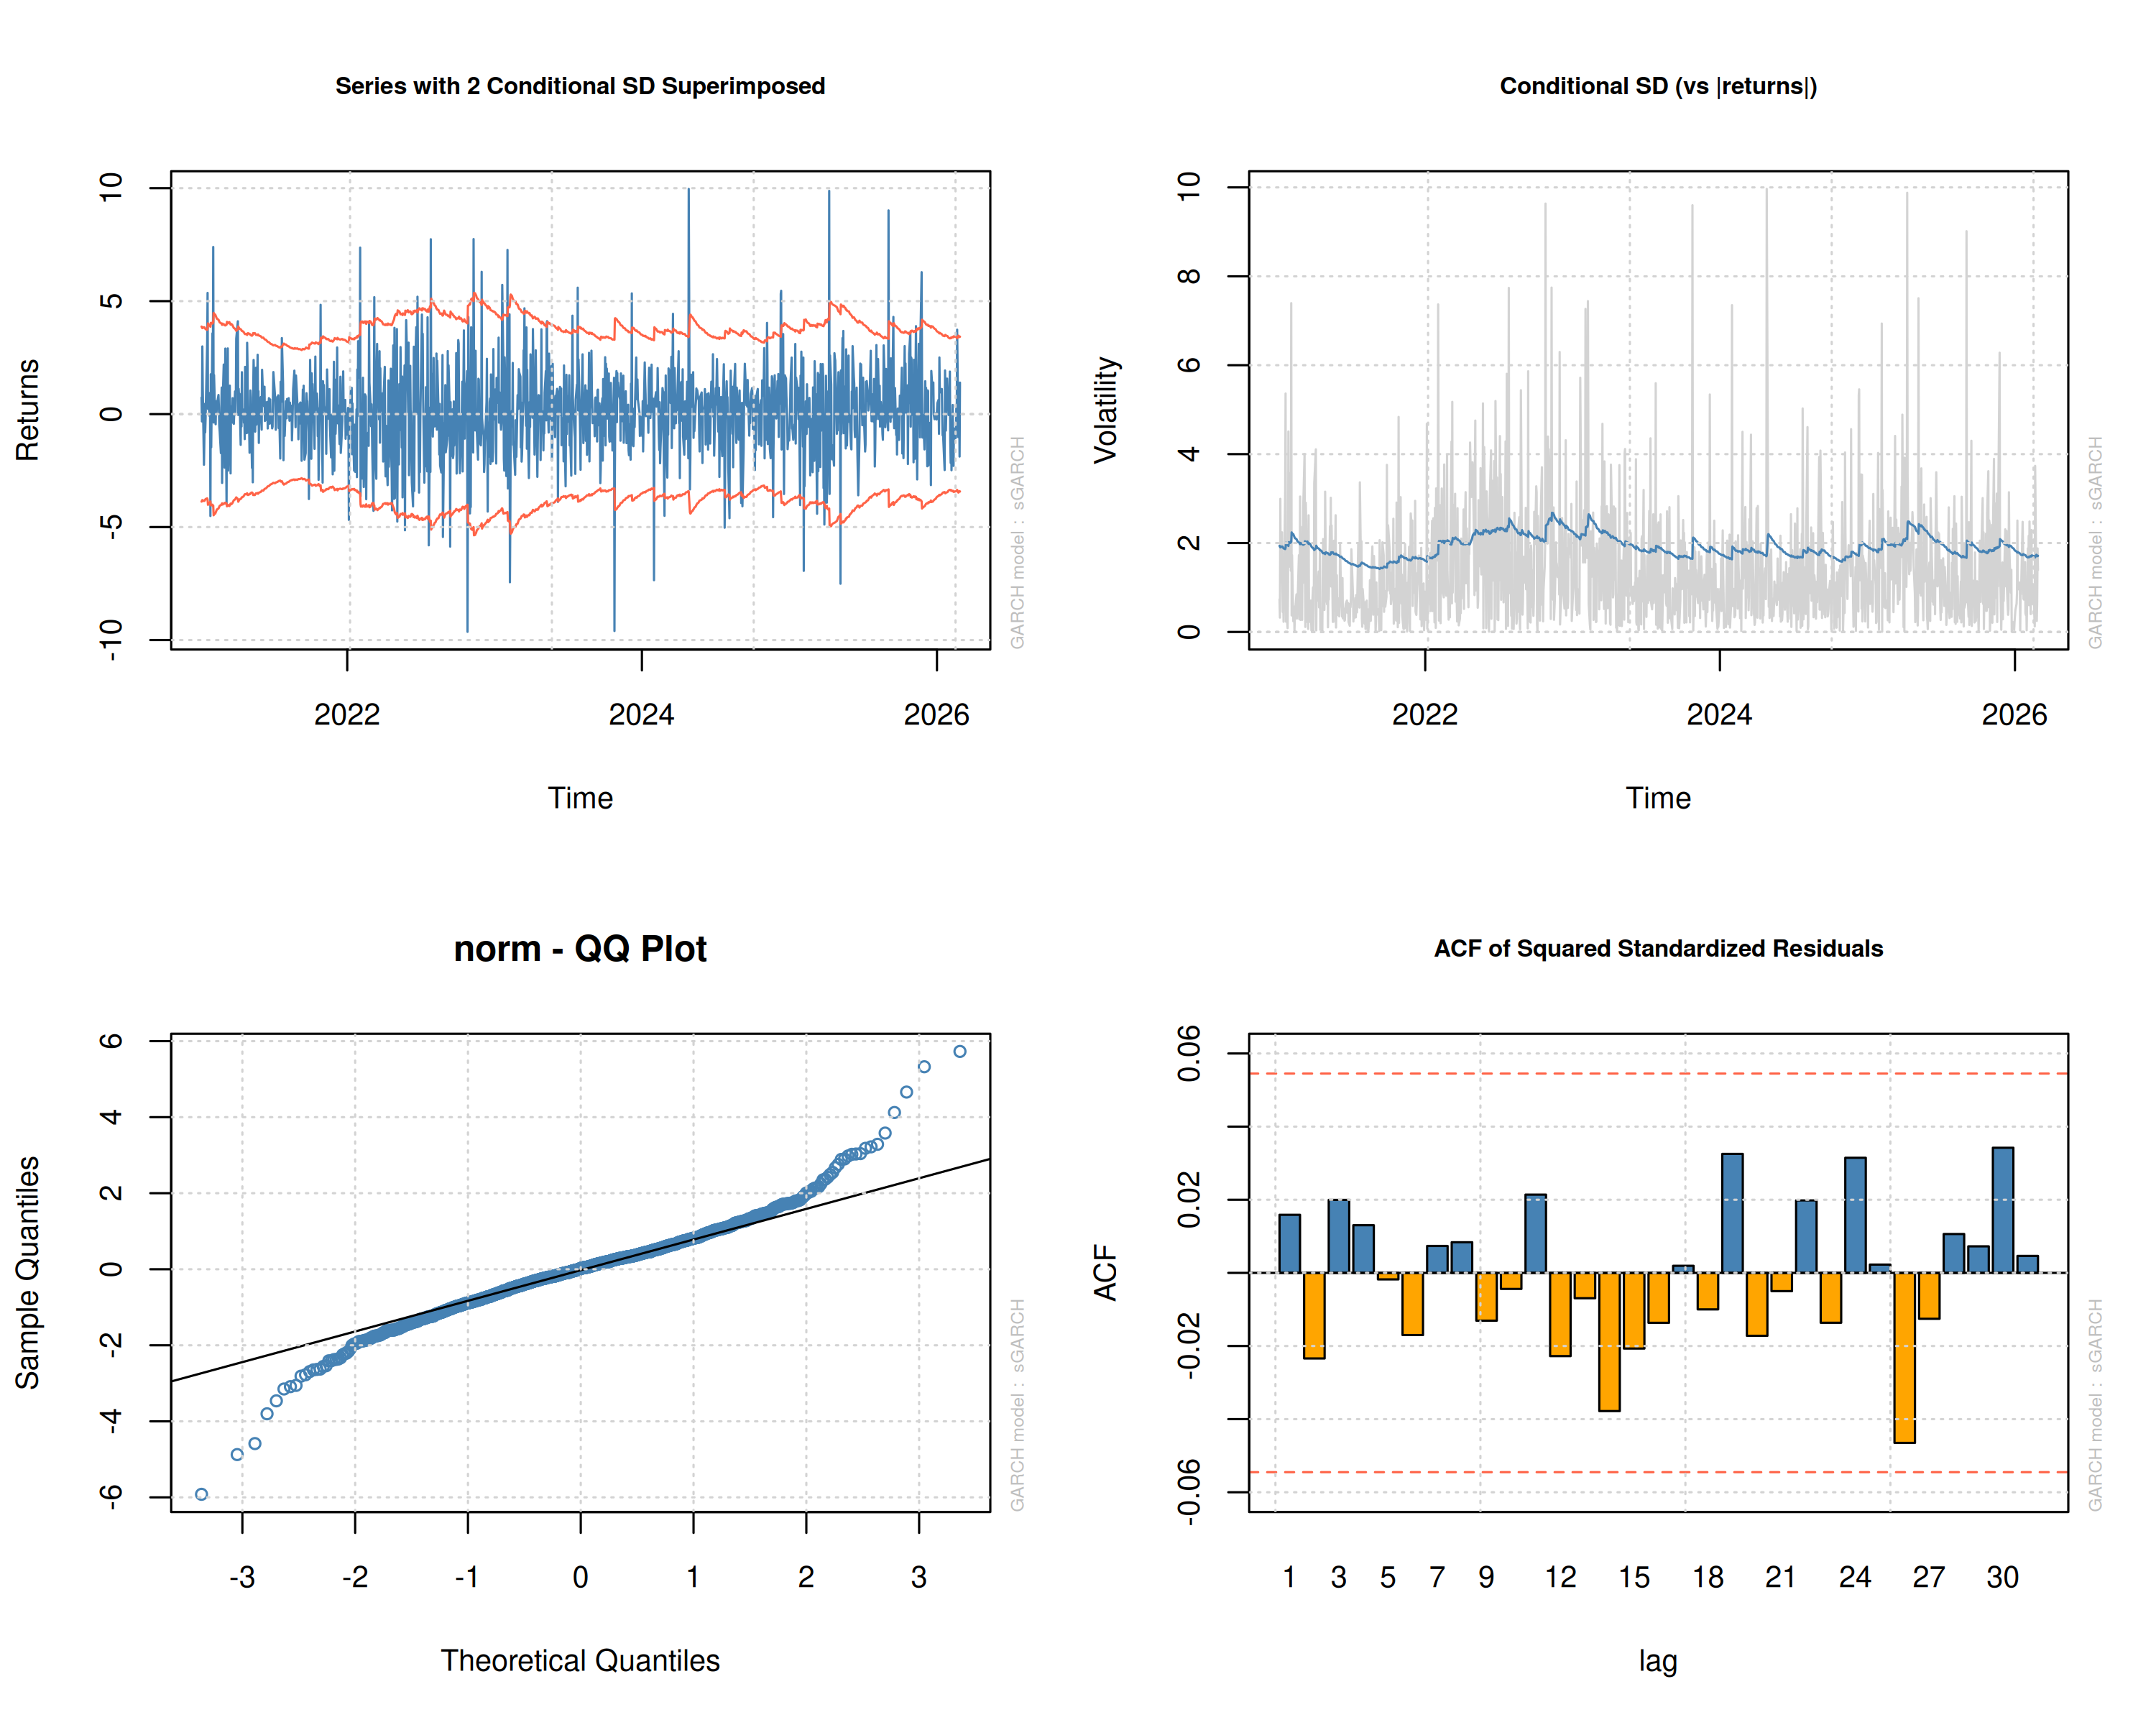

In [12]:
# graficar los valores predichos de la volatilidad por el modelo
# (rugarch tiene 12 gráficos de diagnóstico: which = 1..12)
options(repr.plot.width = 10, repr.plot.height = 8)
par(mfrow = c(2, 2))
invisible(plot(modelo_garch_11, which = 1))   # Serie con bandas de 2 sigma condicional
invisible(plot(modelo_garch_11, which = 3))   # Volatilidad condicional vs |retornos|
invisible(plot(modelo_garch_11, which = 9))   # QQ-plot de residuos estandarizados
invisible(plot(modelo_garch_11, which = 11))  # ACF de residuos estandarizados al cuadrado
par(mfrow = c(1, 1))
options(repr.plot.width = 8, repr.plot.height = 6)

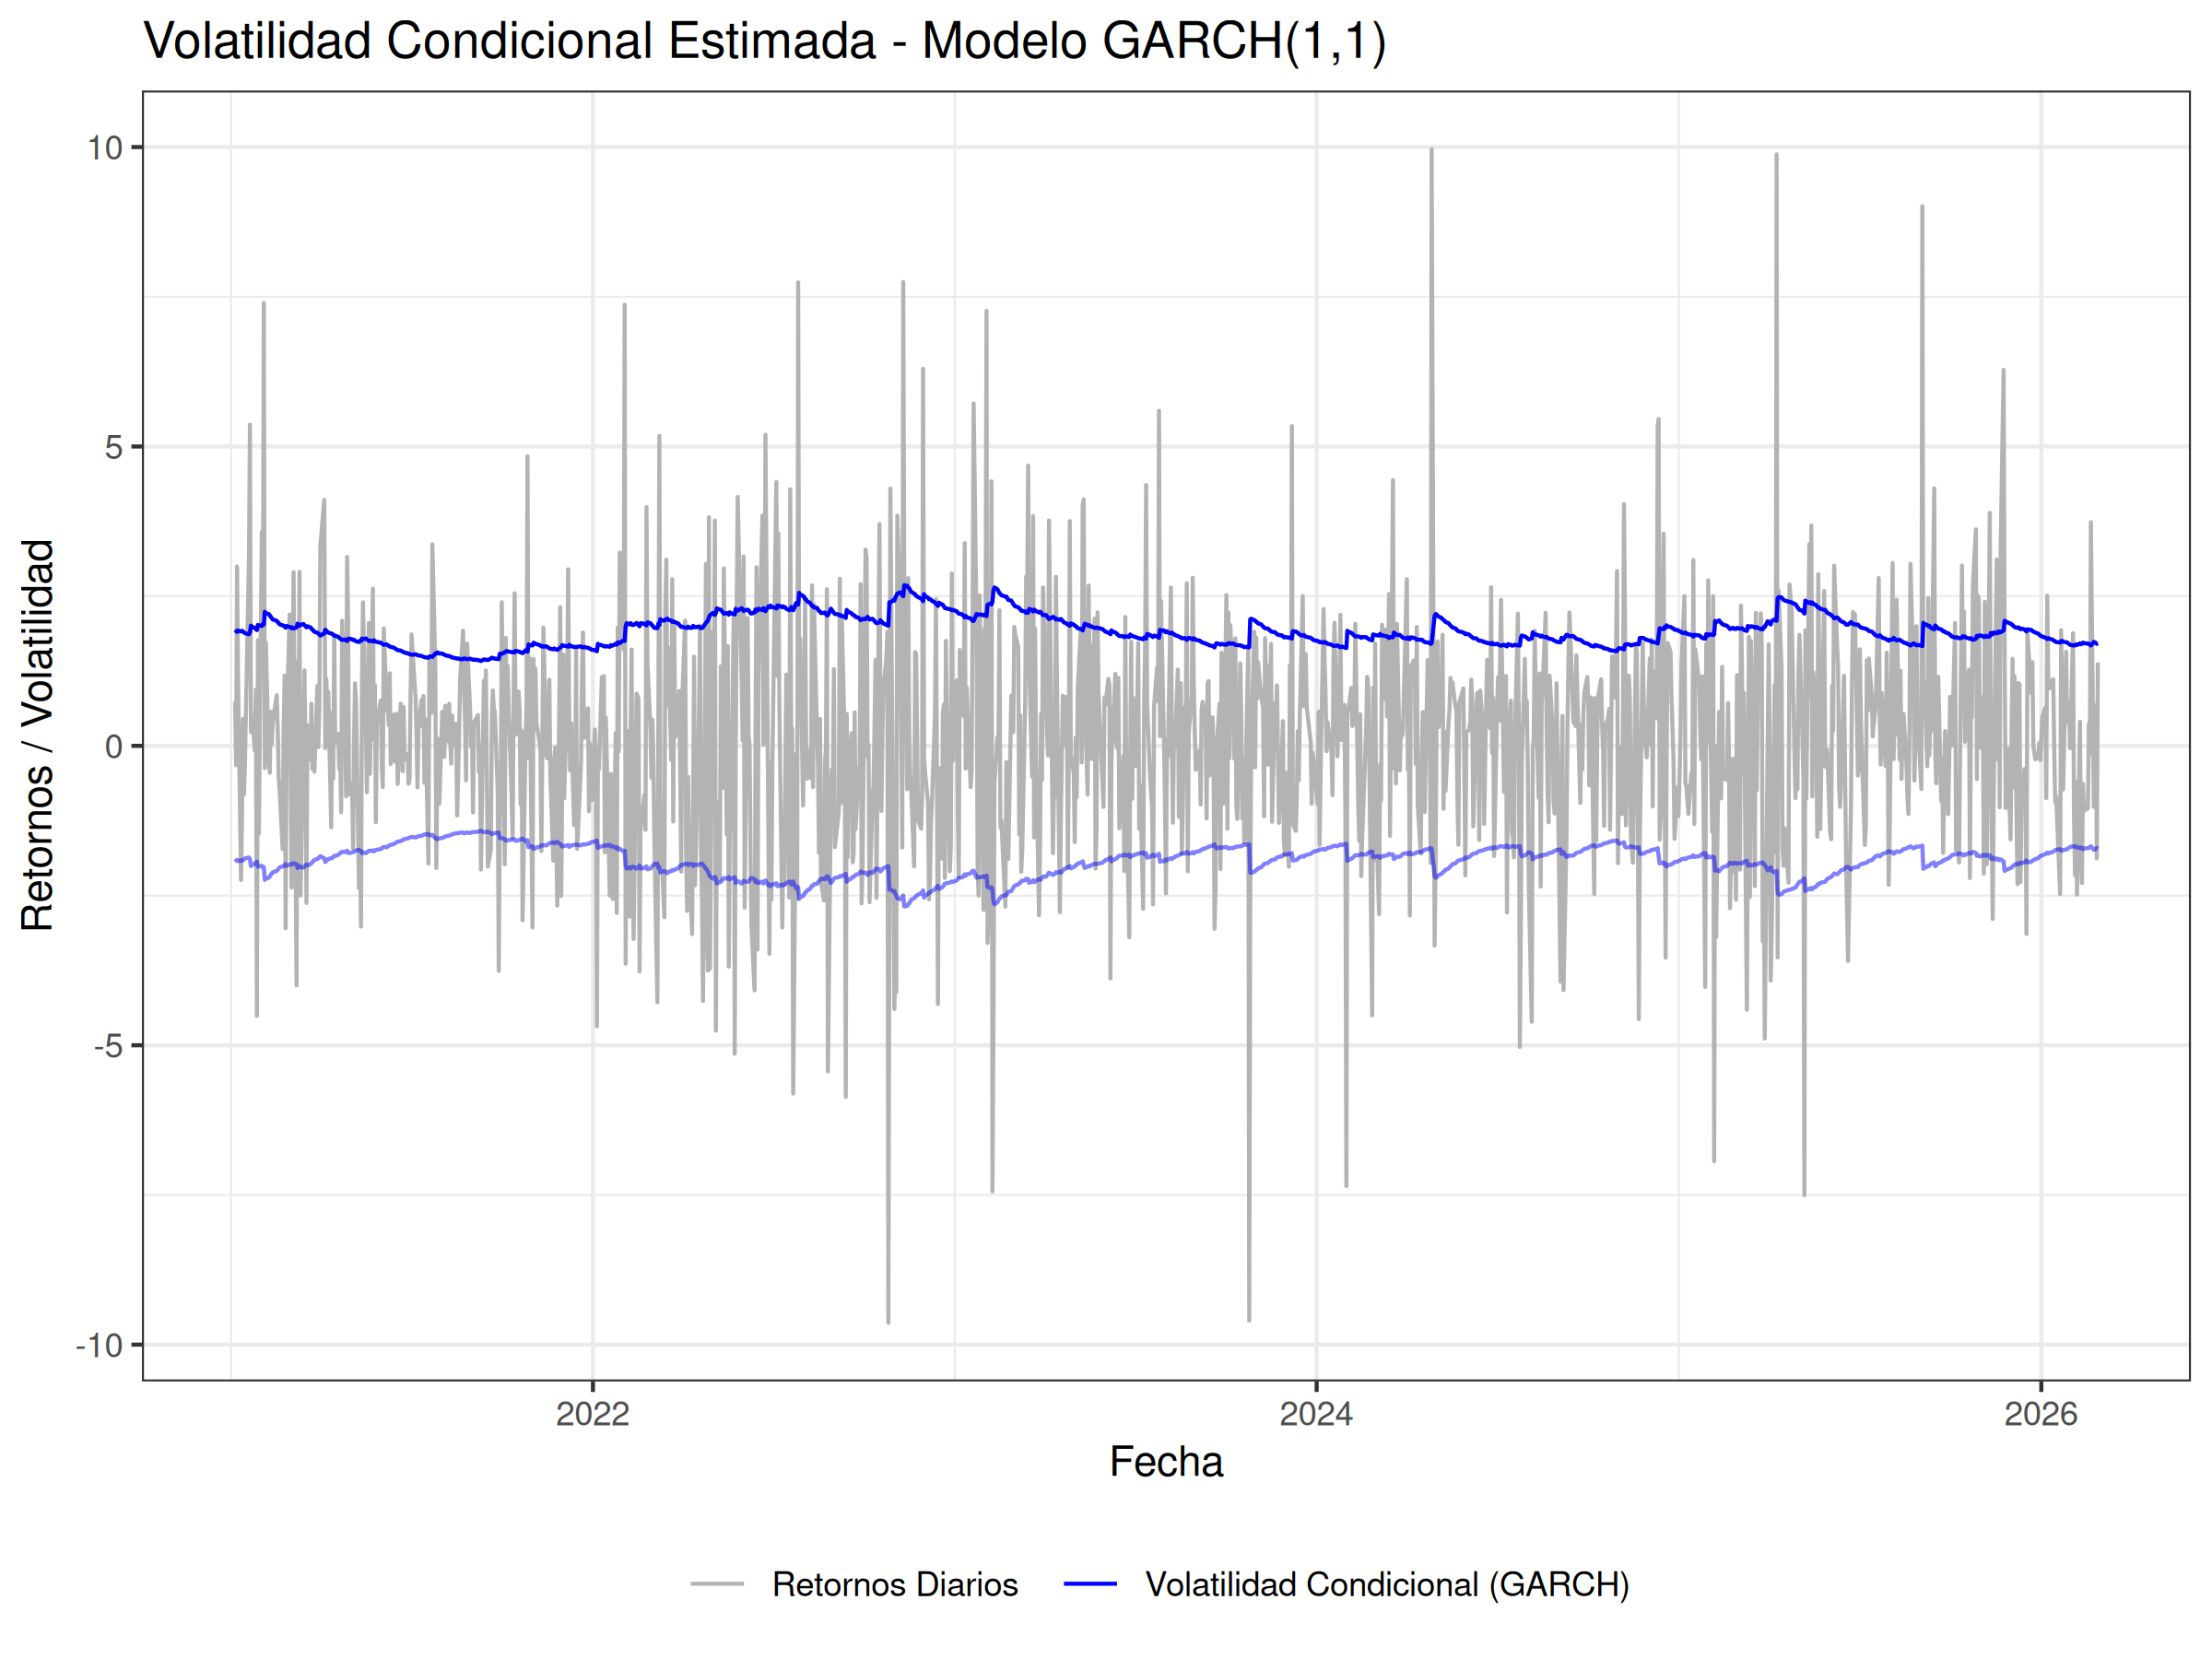

In [13]:
# Extraer la volatilidad condicional estimada (es la desviación estándar sigma_t)
volatilidad_estimada <- tibble(
  fecha       = index(train),
  retorno     = as.numeric(train),
  volatilidad = as.numeric(sigma(modelo_garch_11))
)

volatilidad_estimada |>
  ggplot(aes(fecha)) +
  geom_line(aes(y = retorno, colour = "Retornos Diarios")) +
  geom_line(aes(y = volatilidad, colour = "Volatilidad Condicional (GARCH)")) +
  geom_line(aes(y = -volatilidad), colour = "blue", alpha = 0.5) +
  scale_colour_manual(values = c("Retornos Diarios" = "grey70",
                                 "Volatilidad Condicional (GARCH)" = "blue")) +
  labs(title = "Volatilidad Condicional Estimada - Modelo GARCH(1,1)",
       x = "Fecha", y = "Retornos / Volatilidad", colour = NULL) +
  theme(legend.position = "bottom")

Fecha,Forecast_vol,|r_t|_obs
<date>,<dbl>,<dbl>
2026-03-02,1.7086,1.6280
2026-03-03,1.7113,0.9140
2026-03-04,1.7140,0.0362
2026-03-05,1.7166,0.8370
2026-03-06,1.7192,0.8674
2026-03-09,1.7218,2.6569
2026-03-10,1.7243,0.3006
2026-03-11,1.7268,0.4854
2026-03-12,1.7293,1.6893


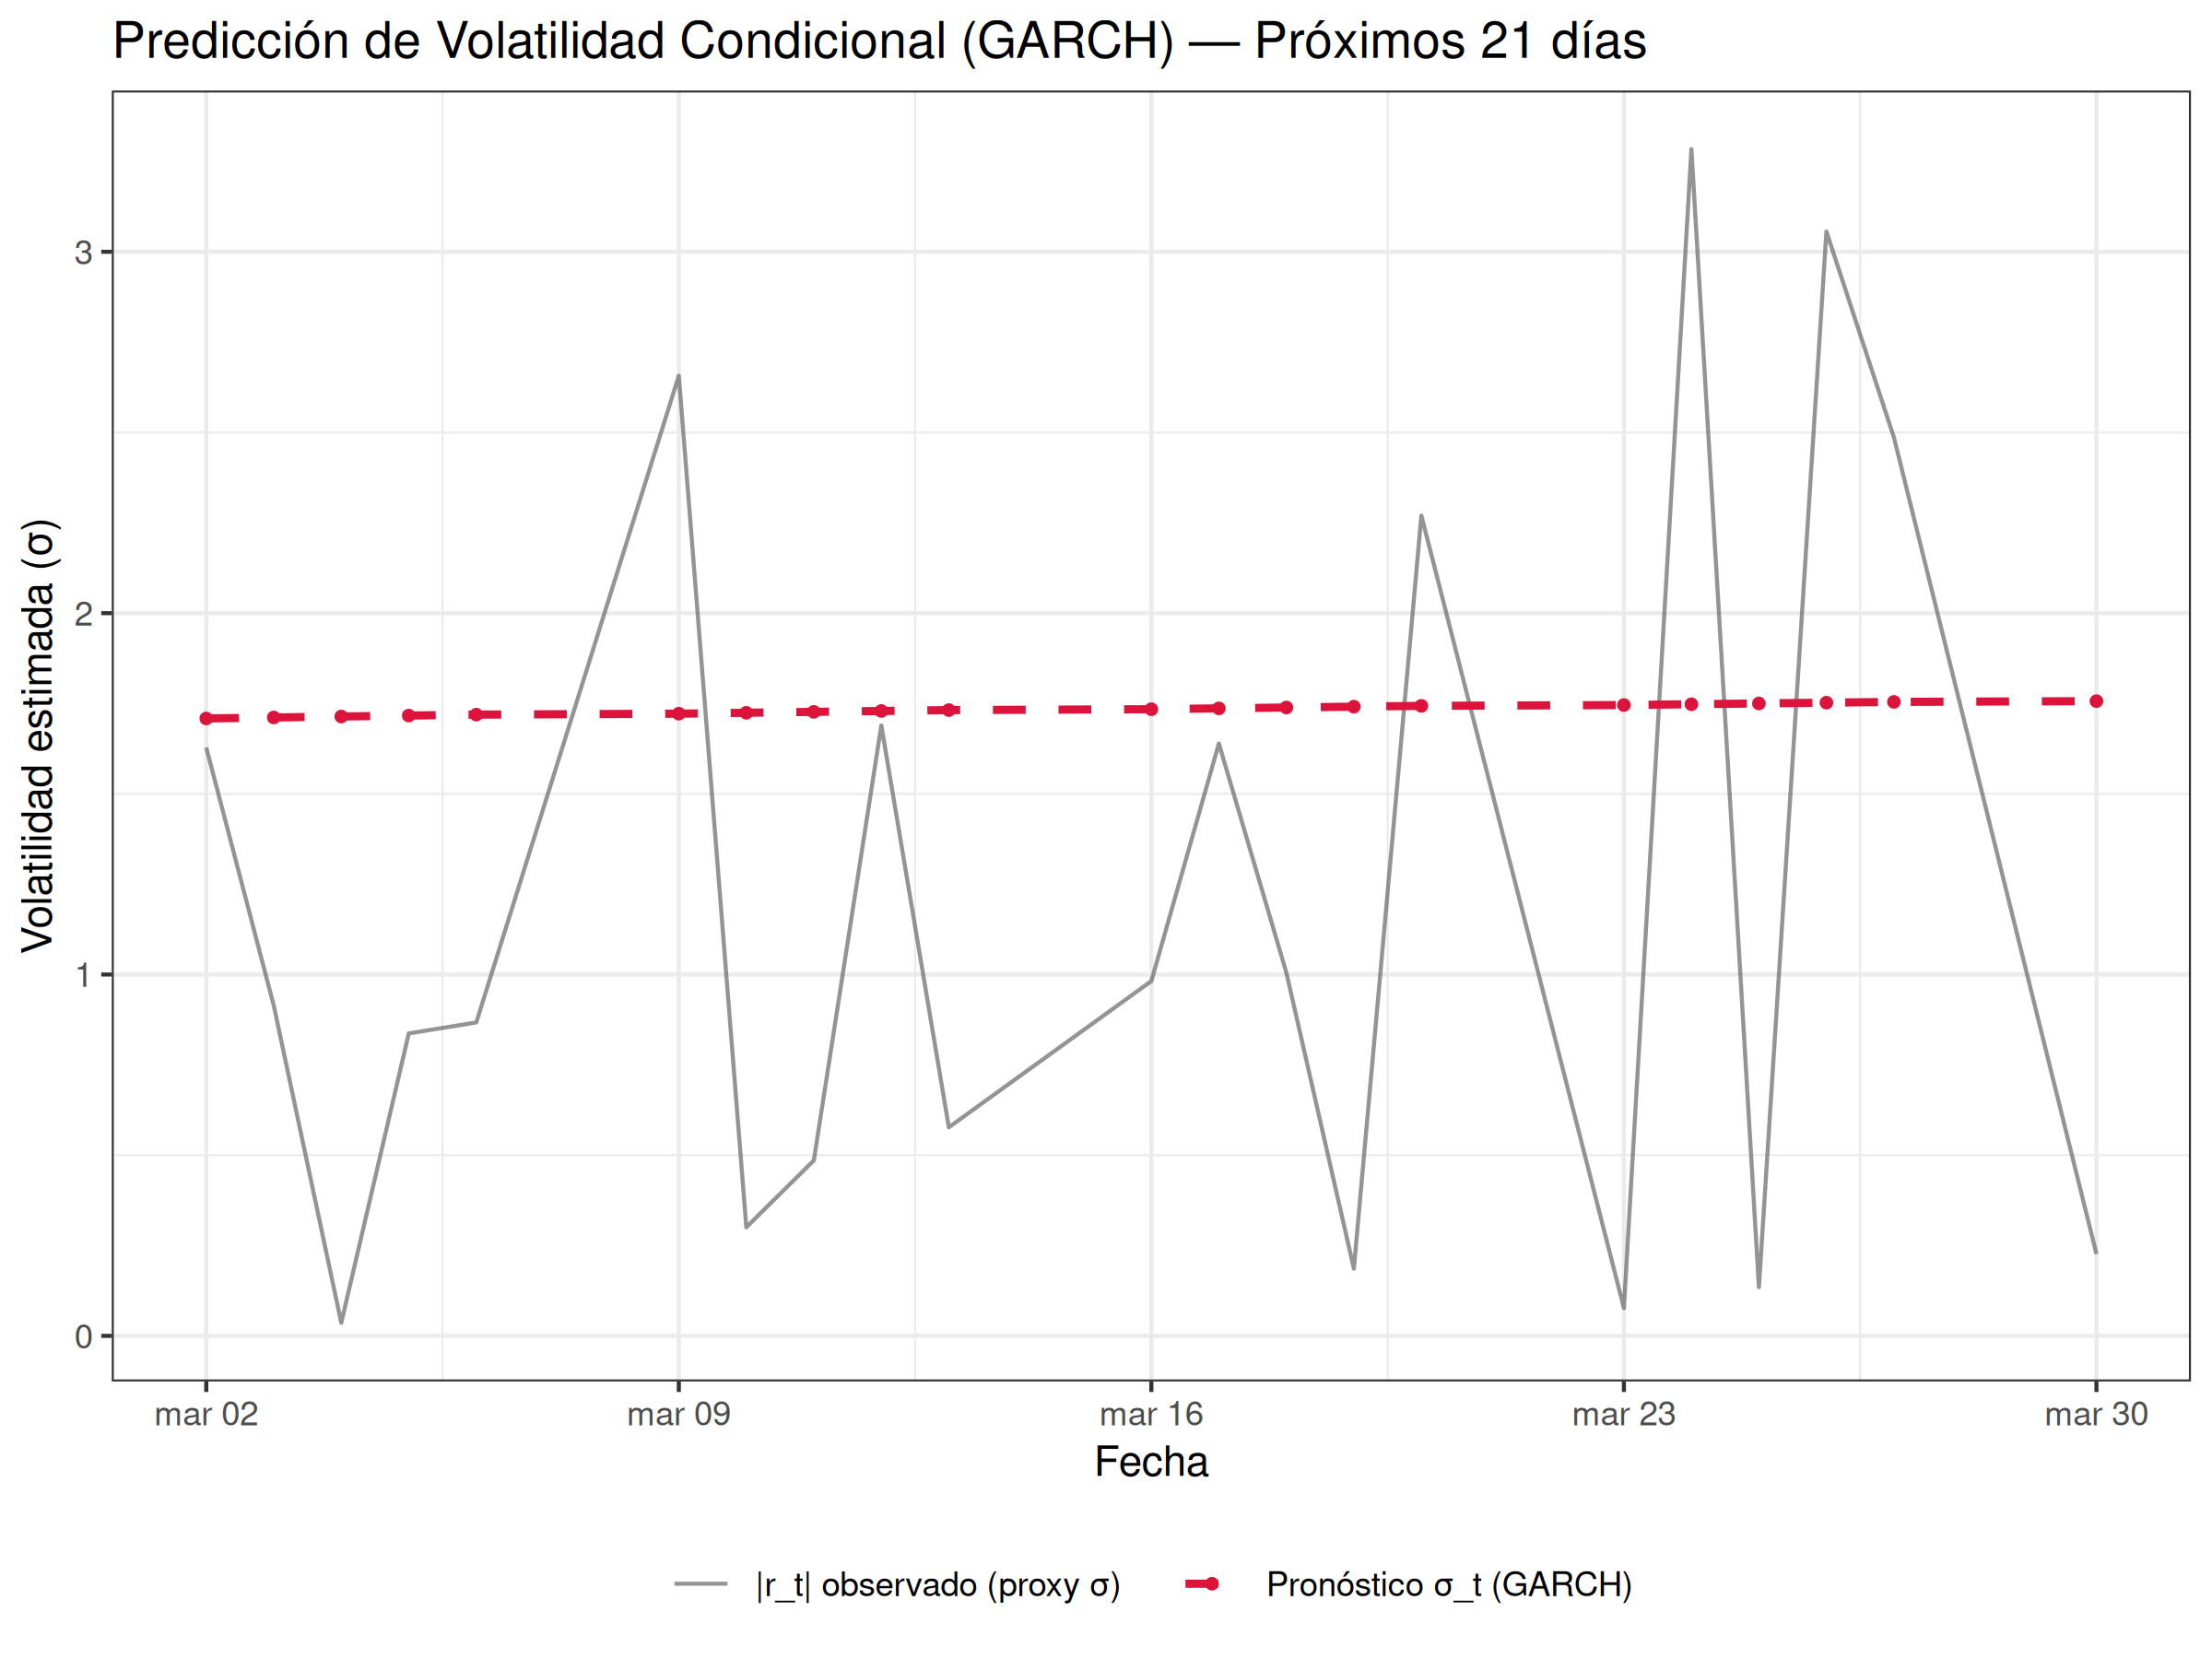

In [14]:
# Pronostico de la volatilidad esperada en el periodo test desde el último dato observado por el modelo
horizonte_t <- length(test)
forecasts   <- ugarchforecast(modelo_garch_11, n.ahead = horizonte_t)

resumen <- tibble(
  Fecha          = index(test),
  `Forecast_vol` = as.numeric(sigma(forecasts)),
  `|r_t|_obs`    = abs(as.numeric(test))
)

# Graficar volatilidad esperada vs volatilidad observada proxy (|r_t|)
resumen |>
  ggplot(aes(Fecha)) +
  geom_line(aes(y = `|r_t|_obs`, colour = "|r_t| observado (proxy σ)"), alpha = 0.7) +
  geom_line(aes(y = Forecast_vol, colour = "Pronóstico σ_t (GARCH)"),
            linetype = "dashed", linewidth = 1) +
  geom_point(aes(y = Forecast_vol, colour = "Pronóstico σ_t (GARCH)"), size = 1) +
  scale_colour_manual(values = c("|r_t| observado (proxy σ)" = "grey40",
                                 "Pronóstico σ_t (GARCH)" = "#DC143C")) +
  labs(title = paste0("Predicción de Volatilidad Condicional (GARCH) — Próximos ", horizonte_t, " días"),
       x = "Fecha", y = "Volatilidad estimada (σ)", colour = NULL) +
  theme(legend.position = "bottom")

resumen |> mutate(across(where(is.numeric), \(x) round(x, 4)))

In [15]:
## Test de normalidad de los residuos del modelo GARCH
# Obtener residuos estandarizados del modelo ajustado: z_t = e_t / sigma_t
std_resid <- residuals(modelo_garch_11, standardize = TRUE)

test_normalidad(std_resid, "Prueba de normalidad residuos GARCH(1, 1)")

Prueba de normalidad residuos GARCH(1, 1)
Estadístico Jarque-Bera: 813.7804 
p-valor: < 2.2e-16 
Resultado: Se rechaza la normalidad (p < 0.05).
Los datos tienen exceso de curtosis o asimetría.


In [16]:
## Restimación del modelo con distribución t-student
spec_garch_11_t <- ugarchspec(
  mean.model         = list(armaOrder = c(0, 0), include.mean = TRUE),
  variance.model     = list(model = "sGARCH", garchOrder = c(1, 1)),
  distribution.model = "std"     # t-student
)

modelo_garch_11_t <- ugarchfit(spec_garch_11_t, data = train)
round(modelo_garch_11_t@fit$matcoef, 4)

,Estimate,Std. Error,t value,Pr(>|t|)
mu,0.1609,0.0444,3.6229,0.0003
omega,0.0336,0.0169,1.9944,0.0461
alpha1,0.0319,0.0062,5.1074,0.0000
beta1,0.9605,0.0052,183.2752,0.0000
shape,4.4680,0.5600,7.9791,0.0000


**Interpretación**

- El parámetro `shape` (grados de libertad de la t-student) es ≈ 4.5 y significativo: los retornos de Google tienen colas mucho más pesadas que la normal.
- Los demás parámetros cambian poco; la persistencia sigue siendo cercana a 1.

## Comparar modelos GARCH

- La evaluación de modelos desempeña un papel fundamental en la valoración del rendimiento y la fiabilidad de los modelos GARCH para la previsión de la volatilidad. Se utilizan diversas técnicas para medir la eficacia de estos modelos :
- **Criterios AIC y BIC :** El criterio de información de Akaike (AIC) y el criterio de información bayesiano (BIC) son medidas estadísticas que se utilizan para evaluar la bondad de ajuste de un modelo, penalizando al mismo tiempo la complejidad del mismo.

> En `rugarch`, `infocriteria()` reporta los criterios divididos por el número de observaciones; para compararlos con los de Python (paquete `arch`) se multiplican por $n$.

In [17]:
# AIC y BIC de los modelos GARCH(1, 1)
n_obs <- length(train)

comparacion <- tibble(
  Modelo     = c("GARCH(1, 1) Normal", "GARCH(1, 1) t-student"),
  `Log-Lik`  = c(likelihood(modelo_garch_11), likelihood(modelo_garch_11_t)),
  AIC        = c(infocriteria(modelo_garch_11)["Akaike", ],
                 infocriteria(modelo_garch_11_t)["Akaike", ]) * n_obs,
  BIC        = c(infocriteria(modelo_garch_11)["Bayes", ],
                 infocriteria(modelo_garch_11_t)["Bayes", ]) * n_obs
) |>
  arrange(AIC)

comparacion
cat("Mejor modelo (menor AIC):", comparacion$Modelo[1], "\n")

Modelo,Log-Lik,AIC,BIC
<chr>,<dbl>,<dbl>,<dbl>
"GARCH(1, 1) t-student",-2592.810,5195.621,5221.444
"GARCH(1, 1) Normal",-2667.469,5342.938,5363.597


Mejor modelo (menor AIC): GARCH(1, 1) t-student 


**Conclusión**

- El GARCH(1,1) con errores t-student tiene mayor log-verosimilitud y menores AIC y BIC: es el mejor modelo para la volatilidad de los retornos de Google.